> **Example output.** This notebook is a saved copy of a completed run in a test environment, so that you can read the results if your own run doesn't work. The values in your lab will differ. To run the batch job yourself, open **ray-batch-inference.ipynb**.

# Batch inference with Ray

This notebook runs a batch job on the Ray cluster in the `ray` namespace. It classifies the sentiment of 1,000 short reviews with the same compact model that the inference service uses: first on one worker, and then across all the workers.

You don't need to change any code. Read the explanation above each cell, select the cell, and then press **Shift+Enter** to run it.

## 1. Connect

Connect to the Ray cluster. The lab set `RAY_ADDRESS` in this notebook's container to the client port of the Ray head. The output lists the **head**, which coordinates the work, and the **workers**, which do it. The head has no CPUs for tasks, so all the work runs on the workers.

In [1]:
import logging
import os
import platform

import ray

logging.getLogger("ray").setLevel(logging.ERROR)  # Hide Ray's informational connection messages
ray.init(log_to_driver=False, logging_level=logging.ERROR)
nodes = [node for node in ray.nodes() if node["Alive"]]
print(f"Connected to {os.environ.get('RAY_ADDRESS', 'a local Ray cluster')}")
print(f"Ray {ray.__version__}, Python {platform.python_version()}")
for node in sorted(nodes, key=lambda item: item["Resources"].get("CPU", 0)):
    role = "head" if "node:__internal_head__" in node["Resources"] else "worker"
    cpus = node["Resources"].get("CPU", 0)
    memory = node["Resources"].get("memory", 0) / 2**30
    print(f"  {role:<7} {node['NodeManagerAddress']:<16} CPUs for tasks: {cpus:g}   memory: {memory:.1f} GiB")
worker_count = sum(1 for node in nodes if node["Resources"].get("CPU", 0) > 0)
print(f"Workers: {worker_count}")

Connected to ray://ray-head:10001
Ray 2.59.0, Python 3.12.14
  head    172.23.0.3       CPUs for tasks: 0   memory: 2.4 GiB
  worker  172.23.0.4       CPUs for tasks: 1   memory: 2.0 GiB
  worker  172.23.0.5       CPUs for tasks: 1   memory: 2.0 GiB
Workers: 2


## 2. Prepare

Create the sample batch, and start one model actor on each worker. An actor is a Python object that Ray keeps on a worker, so each worker loads the model once and keeps it in memory. The workers load the model from their own container image, so nothing large travels over the network.

In [2]:
import time

from samples import make_batch

batch = make_batch(1000)
print(f"Sample batch: {len(batch)} reviews, for example:")
for text in batch[:3]:
    print(f"  {text}")


@ray.remote(num_cpus=1)
class SentimentModel:
    """Loads the compact model once, on the worker that runs this actor."""

    def __init__(self):
        import lab723_batch

        self.model = lab723_batch.BatchModel()

    def classify(self, texts):
        return self.model.classify(texts)


started = time.perf_counter()
models = [SentimentModel.remote() for _ in range(worker_count)]
ray.get([model.classify.remote(["Warming up."]) for model in models])
print(f"Loaded the model on {len(models)} workers in {time.perf_counter() - started:.1f} s")

Sample batch: 1000 reviews, for example:
  The checkout page felt cheap and broke quickly, which wasted my entire morning.
  The firmware update was nothing like the photos, so I returned it the next day.
  The office chair was simple to set up, and the price was fair.
Loaded the model on 2 workers in 1.9 s


## 3. Run on one worker

Split the batch into chunks of 25 reviews, and send every chunk to the first worker. Its actor processes the chunks one after another.

In [3]:
CHUNK_SIZE = 25
chunks = [batch[start:start + CHUNK_SIZE] for start in range(0, len(batch), CHUNK_SIZE)]

started = time.perf_counter()
one_worker_results = ray.get([models[0].classify.remote(chunk) for chunk in chunks])
one_worker_seconds = time.perf_counter() - started
print(f"One worker: {len(batch)} reviews in {len(chunks)} chunks took {one_worker_seconds:.1f} s "
      f"({len(batch) / one_worker_seconds:.0f} reviews per second)")

One worker: 1000 reviews in 40 chunks took 21.0 s (48 reviews per second)


## 4. Run across all workers

Send the same chunks to all the workers in turn, so that they run at the same time. The progress bar advances as each chunk finishes.

In [4]:
import sys

from tqdm import tqdm

all_worker_results = [None] * len(chunks)
started = time.perf_counter()
with tqdm(total=len(batch), unit=" reviews", file=sys.stdout, ncols=80, ascii=True) as progress:
    pending = {models[index % len(models)].classify.remote(chunk): index for index, chunk in enumerate(chunks)}
    while pending:
        done, _ = ray.wait(list(pending), num_returns=1)
        for ref in done:
            index = pending.pop(ref)
            all_worker_results[index] = ray.get(ref)
            progress.update(len(chunks[index]))
all_workers_seconds = time.perf_counter() - started
print(f"All {len(models)} workers: {len(batch)} reviews took {all_workers_seconds:.1f} s "
      f"({len(batch) / all_workers_seconds:.0f} reviews per second)")

100%|#################################| 1000/1000 [00:11<00:00, 84.40 reviews/s]
All 2 workers: 1000 reviews took 11.9 s (84 reviews per second)


## 5. Compare

Check that both runs gave the same answers, look at a few results, and compare the elapsed times. For a batch this small, splitting the work and scheduling the tasks take a noticeable share of the total time, so the speedup can be less than the number of workers.

Both runs gave the same labels: True
label
NEGATIVE    588
POSITIVE    412


,review,label,score
0,"The checkout page felt cheap and broke quickly, which wasted my entire morning.",NEGATIVE,0.9998
1,"The firmware update was nothing like the photos, so I returned it the next day.",NEGATIVE,0.9923
2,"The office chair was simple to set up, and the price was fair.",POSITIVE,0.9973
3,"The firmware update was simple to set up, so I recommended it to my whole team.",POSITIVE,0.9988
4,"The subscription plan kept working without a single problem, and I can't imagine going back.",NEGATIVE,0.9931
5,"The wireless headphones was nothing like the photos, which wasted my entire morning.",NEGATIVE,0.9997
6,"The coffee maker worked perfectly on the first try, and I would happily buy it again.",POSITIVE,0.9996
7,"The fitness tracker crashed every time I opened it, and I regret buying it.",NEGATIVE,0.9995


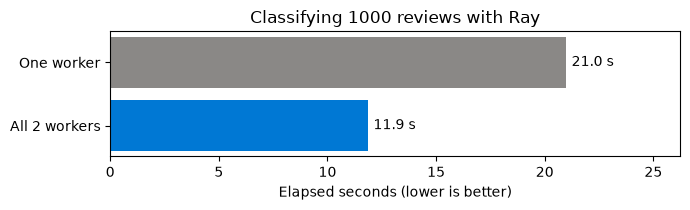

Speedup across all workers: 1.8x


In [5]:
import matplotlib.pyplot as plt
import pandas as pd

one_worker = [result for chunk in one_worker_results for result in chunk]
all_workers = [result for chunk in all_worker_results for result in chunk]
same = [result["label"] for result in one_worker] == [result["label"] for result in all_workers]
print(f"Both runs gave the same labels: {same}")

pd.set_option("display.max_colwidth", 100)
results = pd.DataFrame({
    "review": batch,
    "label": [result["label"] for result in all_workers],
    "score": [result["score"] for result in all_workers],
})
print(results["label"].value_counts().to_string())
display(results.head(8))

names = ["One worker", f"All {len(models)} workers"]
seconds = [one_worker_seconds, all_workers_seconds]
fig, ax = plt.subplots(figsize=(7, 2.2))
bars = ax.barh(names, seconds, color=["#8a8886", "#0078d4"])
ax.bar_label(bars, labels=[f"{value:.1f} s" for value in seconds], padding=4)
ax.set_xlabel("Elapsed seconds (lower is better)")
ax.set_xlim(0, max(seconds) * 1.25)
ax.invert_yaxis()
ax.set_title(f"Classifying {len(batch)} reviews with Ray")
plt.tight_layout()
plt.show()
print(f"Speedup across all workers: {one_worker_seconds / all_workers_seconds:.1f}x")